# Sigma-convergência entre os estados brasileiros, 2002–2023

Calcula, ano a ano, o desvio-padrão do logaritmo e o coeficiente de variação do PIB per capita estadual, com e sem o Distrito Federal (seção 4.3 do TCC).

Os dados vêm do Ipeadata e devem estar na pasta `../dados_usados` (ver o README do repositório).

In [1]:
# ----------------------------------------------------------------------------
# 1. BIBLIOTECAS E PARÂMETROS
# ----------------------------------------------------------------------------
import os                             # criação das pastas de saída
import numpy as np                    # operações numéricas; usamos np.log
import pandas as pd                   # manipulação de tabelas (DataFrames)
import matplotlib.pyplot as plt       # gráficos

# Caminho do arquivo baixado do Ipeadata (série PIBPCE), guardado na pasta
# TCC\dados_usados. O ".." sobe da pasta deste notebook para a pasta TCC.
CAMINHO = os.path.join("..", "dados_usados",
                       "PIBPCE_pib_estadual_per_capita_precos_2010_[17-08-2026].csv")

ANO_INICIAL = 2002
ANO_FINAL   = 2023

# Pastas onde os resultados são salvos. exist_ok=True evita erro se já existirem.
for pasta in ["resultados/figuras", "resultados/tabelas", "dados/tratados"]:
    os.makedirs(pasta, exist_ok=True)

In [2]:
# ----------------------------------------------------------------------------
# 2. LEITURA E MONTAGEM DO PAINEL (igual ao notebook da beta)
# ----------------------------------------------------------------------------
# skiprows=1 pula a linha com o título da série; utf-8-sig remove o BOM do arquivo
df = pd.read_csv(CAMINHO, skiprows=1, encoding="utf-8-sig")

# Remove a coluna vazia criada pela vírgula no fim de cada linha
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

# Colunas cujo nome é um ano
anos = [c for c in df.columns if c.isdigit()]

# Formato longo: uma linha por estado-ano
painel = df.melt(
    id_vars=["Sigla", "Código", "Estado"],
    value_vars=anos,
    var_name="ano",
    value_name="pibpc_real",
)
painel["ano"] = painel["ano"].astype(int)

# Logaritmo natural do PIB per capita: a sigma-convergência é definida sobre o
# log da renda, porque o desvio-padrão do log mede desigualdade PROPORCIONAL
# (se todos os estados dobrassem de renda, ele não mudaria).
painel["ln_pibpc"] = np.log(painel["pibpc_real"])

# ---- Validações antes de prosseguir --------------------------------------
assert len(painel) == 27 * 22, f"Esperado 594 linhas, obtido {len(painel)}"
assert painel["Sigla"].nunique() == 27, "Não há 27 UF"
assert painel["pibpc_real"].isna().sum() == 0, "Há valores ausentes"
print(f"Painel validado: {len(painel)} observações, {painel['Sigla'].nunique()} UF, "
      f"{painel['ano'].min()}-{painel['ano'].max()}")

Painel validado: 594 observações, 27 UF, 2002-2023


In [3]:
# ----------------------------------------------------------------------------
# 3. MEDIDAS DE DISPERSÃO, ANO A ANO
# ----------------------------------------------------------------------------
def medidas_dispersao(dados):
    """
    Para cada ano, calcula a dispersão da renda per capita entre as unidades.

    - dp_ln: desvio-padrão do ln do PIB per capita (medida principal)
    - cv:    coeficiente de variação = desvio-padrão em reais / média em reais

    ddof=0 usa o desvio-padrão POPULACIONAL (divide por n, não por n - 1).
    É a escolha coerente com o fato de trabalharmos com o universo das UF, e não
    com uma amostra. A escolha não altera a trajetória: muda todos os anos pelo
    mesmo fator.
    """
    por_ano = dados.groupby("ano")    # agrupa as linhas de cada ano (27 ou 26 UF)
    return pd.DataFrame({
        "dp_ln": por_ano["ln_pibpc"].std(ddof=0),
        "cv":    por_ano["pibpc_real"].std(ddof=0) / por_ano["pibpc_real"].mean(),
        "n":     por_ano["Sigla"].nunique(),
    })


# Todas as 27 UF (análise principal)
disp = medidas_dispersao(painel)

# Sem o Distrito Federal (robustez, coerente com a regressão de beta): o DF tem
# quase o dobro da renda do 2º colocado, e a sua renda reflete a administração
# federal, não uma base produtiva comparável à dos demais estados.
disp_sdf = medidas_dispersao(painel[painel["Sigla"] != "DF"])

# Junta tudo numa única tabela, uma linha por ano
tabela_anual = pd.DataFrame({
    "dp_ln":        disp["dp_ln"],
    "cv":           disp["cv"],
    "dp_ln_sem_DF": disp_sdf["dp_ln"],
    "cv_sem_DF":    disp_sdf["cv"],
})
tabela_anual.index.name = "ano"

print(tabela_anual.round(4).to_string())

       dp_ln      cv  dp_ln_sem_DF  cv_sem_DF
ano                                          
2002  0.5007  0.6252        0.4269     0.4307
2003  0.5005  0.5923        0.4364     0.4348
2004  0.5058  0.5917        0.4436     0.4409
2005  0.4991  0.6016        0.4332     0.4417
2006  0.4805  0.5940        0.4119     0.4301
2007  0.4939  0.5893        0.4302     0.4389
2008  0.4858  0.5672        0.4260     0.4294
2009  0.4716  0.5693        0.4055     0.4087
2010  0.4749  0.5831        0.4059     0.4128
2011  0.4755  0.5566        0.4157     0.4201
2012  0.4657  0.5367        0.4100     0.4158
2013  0.4558  0.5172        0.4039     0.4096
2014  0.4465  0.5188        0.3916     0.4045
2015  0.4411  0.5256        0.3810     0.3942
2016  0.4404  0.5350        0.3767     0.3922
2017  0.4296  0.5177        0.3678     0.3817
2018  0.4357  0.5226        0.3746     0.3887
2019  0.4366  0.5279        0.3736     0.3867
2020  0.4297  0.4971        0.3762     0.3880
2021  0.4409  0.4851        0.3994

In [4]:
# ----------------------------------------------------------------------------
# 4. RESUMO: INÍCIO, FIM, VARIAÇÃO E MÍNIMO DE CADA MEDIDA
# ----------------------------------------------------------------------------
nomes = {
    "dp_ln":        "Desvio-padrão do ln (27 UF)",
    "cv":           "Coeficiente de variação (27 UF)",
    "dp_ln_sem_DF": "Desvio-padrão do ln (sem o DF)",
    "cv_sem_DF":    "Coeficiente de variação (sem o DF)",
}

linhas = []
for col, nome in nomes.items():
    serie = tabela_anual[col]
    linhas.append({
        "Medida":              nome,
        f"{ANO_INICIAL}":      serie[ANO_INICIAL],
        f"{ANO_FINAL}":        serie[ANO_FINAL],
        # Variação percentual entre o primeiro e o último ano:
        # negativa = a dispersão caiu (sigma-convergência no período)
        "Variação (%)":        (serie[ANO_FINAL] / serie[ANO_INICIAL] - 1) * 100,
        "Mínimo":              serie.min(),
        "Ano do mínimo":       serie.idxmin(),
        # Variação do ano do mínimo até o fim: positiva = a dispersão voltou a subir
        "Do mínimo ao fim (%)": (serie[ANO_FINAL] / serie.min() - 1) * 100,
    })

resumo_sigma = pd.DataFrame(linhas)
print(resumo_sigma.round(4).to_string(index=False))

                            Medida   2002   2023  Variação (%)  Mínimo  Ano do mínimo  Do mínimo ao fim (%)
       Desvio-padrão do ln (27 UF) 0.5007 0.4333      -13.4532  0.4296           2017                0.8713
   Coeficiente de variação (27 UF) 0.6252 0.4933      -21.1008  0.4851           2021                1.6922
    Desvio-padrão do ln (sem o DF) 0.4269 0.3816      -10.6136  0.3678           2017                3.7371
Coeficiente de variação (sem o DF) 0.4307 0.3869      -10.1540  0.3817           2017                1.3731


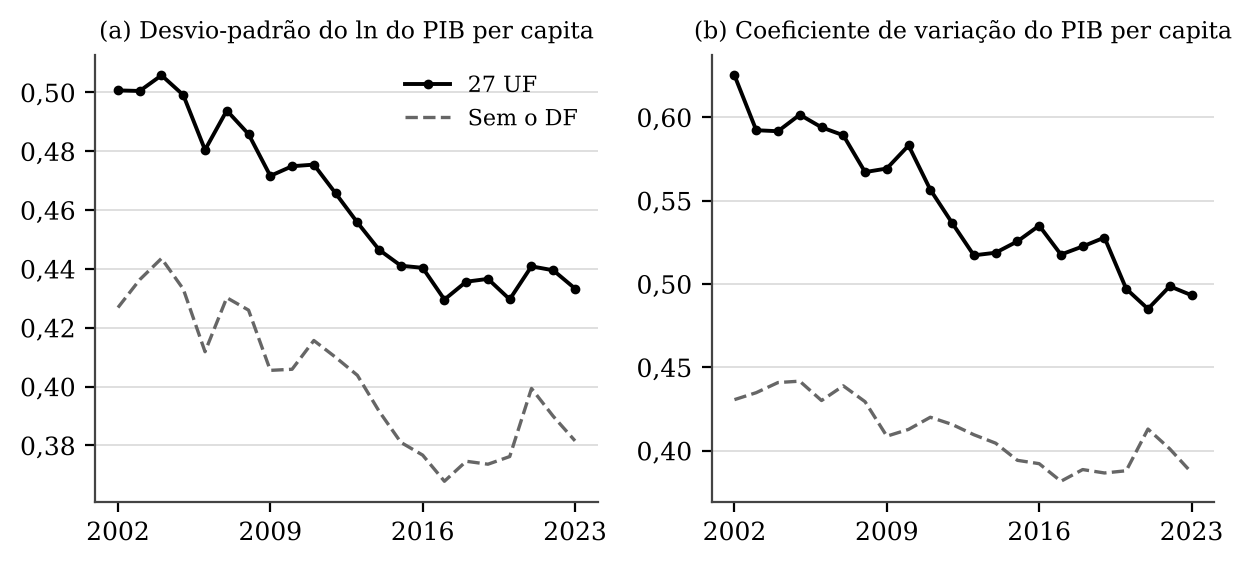

In [5]:
# ----------------------------------------------------------------------------
# 5. GRÁFICOS (Figura 6 do trabalho escrito)
# ----------------------------------------------------------------------------
# Dois painéis lado a lado, com o mesmo eixo de tempo:
# (a) desvio-padrão do ln, medida principal; (b) coeficiente de variação.
# Em cada um, a linha cheia usa as 27 UF e a tracejada exclui o DF.
# Padrão das figuras do texto: preto e cinza, fonte serifada de 9 pt, vírgula decimal,
# sem título (título e fonte ficam no Word), no tamanho de impressão (16 cm = 6,3 pol.).
from matplotlib.ticker import FuncFormatter
VIRG = FuncFormatter(lambda v, pos: f"{v:.2f}".replace(".", ","))
with plt.rc_context({"font.family": "serif", "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": "#444444"}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(6.3, 2.9), sharex=True)
    for ax, col, titulo in [(ax1, "dp_ln", "(a) Desvio-padrão do ln do PIB per capita"),
                            (ax2, "cv", "(b) Coeficiente de variação do PIB per capita")]:
        ax.plot(tabela_anual.index, tabela_anual[col], color="black", lw=1.4,
                marker="o", ms=2.5, label="27 UF")
        ax.plot(tabela_anual.index, tabela_anual[col + "_sem_DF"], color="#666666",
                lw=1.2, ls="--", label="Sem o DF")
        ax.set_title(titulo, fontsize=8.5)
        ax.set_xticks(range(ANO_INICIAL, ANO_FINAL + 1, 7))
        ax.yaxis.set_major_formatter(VIRG)
        ax.grid(axis="y", color="#d9d9d9", lw=0.6)
    ax1.legend(frameon=False, fontsize=8, loc="upper right")
    plt.tight_layout()
    plt.savefig("resultados/figuras/sigma_convergencia.png", dpi=300, bbox_inches="tight")
    plt.show()

In [6]:
# ----------------------------------------------------------------------------
# 6. SALVAR PRODUTOS
# ----------------------------------------------------------------------------
tabela_anual.to_csv("resultados/tabelas/sigma_anual.csv")
resumo_sigma.to_csv("resultados/tabelas/resumo_sigma.csv", index=False)